<a href="https://colab.research.google.com/github/nagireddi-yashaswini/quantum-computing-hacakthon/blob/main/Quantum_Vision_Transformer_QViT_MNIST_FashionMNIST_28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Vision Transformer (QViT) for MNIST and Fashion-MNIST

This notebook implements a **hybrid quantum-classical image classifier**.

- Official train/test splits are preserved.
- Two classes are selected from each dataset.
- Images are resized to **4×4** and divided into four **2×2 patches**.
- Classical self-attention learns relationships between image patches.
- A trainable 4-qubit PennyLane circuit transforms the pooled attention features.
- A classical neural network produces the final two-class prediction.
- A classical attention baseline uses the same image preprocessing and data splits.

**Important:** The attention operation in this starter implementation is classical self-attention. The quantum circuit is a trainable quantum feature-processing block after attention. This is a hybrid QViT-style architecture, not a claim that the attention calculation itself is quantum.

The default run uses small, balanced subsets so the notebook can be tested in Colab. Increase the subset sizes and epochs after the pipeline works.

In [2]:
# Cell 1 — Install required packages
!pip -q install pennylane torchvision scikit-learn matplotlib seaborn pandas

In [3]:
# Cell 2 — Imports and reproducibility
import os, time, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset, Subset
from torchvision import datasets, transforms

import pennylane as qml

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, roc_auc_score, classification_report,
    roc_curve
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# PennyLane's default.qubit simulator is used for the quantum layer.
# CPU is selected for reliable compatibility with the simulator.
device = torch.device("cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)
print("PennyLane:", qml.__version__)

Device: cpu
PyTorch: 2.14.1+cpu
PennyLane: 0.45.1


## Dataset setup

MNIST uses digits **0 and 1**. Fashion-MNIST uses **T-shirt/top (0)** and **Trouser (1)**. We filter the official training and testing datasets independently, so no test images enter training.

In [4]:
# Cell 3 — Configuration
IMAGE_SIZE = 4
PATCH_SIZE = 2
EMBED_DIM = 4                 # Must equal the number of quantum input features
N_QUBITS = 4
N_QUANTUM_LAYERS = 2
BATCH_SIZE = 32
EPOCHS = 3                    # Increase to 5–15 for a longer experiment
LEARNING_RATE = 0.001

# Small balanced subsets for a manageable first Colab run.
# Set either value to None to use all available examples in that split.
TRAIN_PER_CLASS = 500
TEST_PER_CLASS = 200

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

def load_two_class_dataset(dataset_name, train=True):
    if dataset_name == "MNIST":
        ds = datasets.MNIST(
            root="./data", train=train, download=True, transform=transform
        )
    elif dataset_name == "FashionMNIST":
        ds = datasets.FashionMNIST(
            root="./data", train=train, download=True, transform=transform
        )
    else:
        raise ValueError("Unknown dataset name")

    # Select labels 0 and 1 only. Keep the original official split.
    selected_indices = [
        i for i, (_, label) in enumerate(ds) if int(label) in (0, 1)
    ]

    # Use a reproducible, balanced subset independently within each split.
    if train:
        limit = TRAIN_PER_CLASS
    else:
        limit = TEST_PER_CLASS

    if limit is not None:
        class0 = [i for i in selected_indices if int(ds[i][1]) == 0]
        class1 = [i for i in selected_indices if int(ds[i][1]) == 1]
        rng = np.random.default_rng(SEED)
        class0 = rng.choice(class0, size=min(limit, len(class0)), replace=False).tolist()
        class1 = rng.choice(class1, size=min(limit, len(class1)), replace=False).tolist()
        selected_indices = class0 + class1
        rng.shuffle(selected_indices)

    subset = Subset(ds, selected_indices)

    images, labels = [], []
    for image, label in subset:
        images.append(image)
        labels.append(int(label))  # labels remain 0 and 1

    X = torch.stack(images).float()       # shape: (N, 1, 4, 4)
    y = torch.tensor(labels, dtype=torch.long)
    return TensorDataset(X, y)

mnist_train = load_two_class_dataset("MNIST", train=True)
mnist_test = load_two_class_dataset("MNIST", train=False)
fashion_train = load_two_class_dataset("FashionMNIST", train=True)
fashion_test = load_two_class_dataset("FashionMNIST", train=False)

print("MNIST:", len(mnist_train), "train,", len(mnist_test), "test")
print("Fashion-MNIST:", len(fashion_train), "train,", len(fashion_test), "test")

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 528kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.66MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.53MB/s]
100%|██████████| 26.4M/26.4M [00:02<00:00, 12.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.6MB/s]


MNIST: 1000 train, 400 test
Fashion-MNIST: 1000 train, 400 test


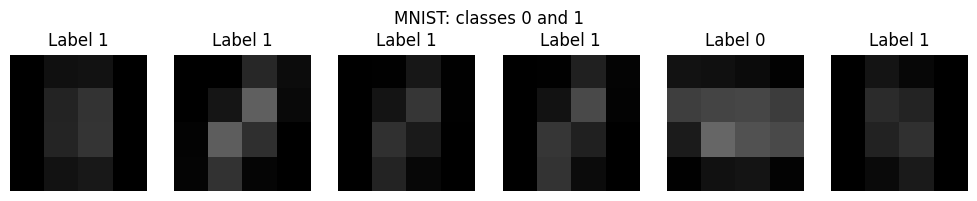

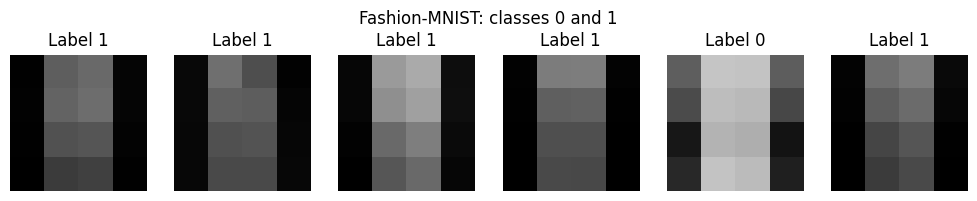

In [5]:
# Cell 4 — Inspect sample images
def show_samples(dataset, title):
    fig, axes = plt.subplots(1, 6, figsize=(10, 2))
    for i, ax in enumerate(axes):
        image, label = dataset[i]
        ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Label {label}")
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_samples(mnist_train, "MNIST: classes 0 and 1")
show_samples(fashion_train, "Fashion-MNIST: classes 0 and 1")

## Model architecture

Each 4×4 image is split into four 2×2 patches. A linear layer embeds each patch into a 4-dimensional vector. A learnable class token and positional embeddings are added. Multi-head self-attention operates across the four patches and class token.

For QViT, the class-token representation is passed through a 4-qubit variational circuit using angle embedding, trainable entangling layers, and Pauli-Z measurements. The four measured expectation values feed a classical classifier.

The classical baseline has the same patch embedding and attention pathway but uses the class-token representation directly, without a quantum circuit.

In [6]:
# Cell 5 — Quantum circuit and QViT model
N_PATCHES = (IMAGE_SIZE // PATCH_SIZE) ** 2

quantum_device = qml.device("default.qubit", wires=N_QUBITS, shots=None)

@qml.qnode(quantum_device, interface="torch", diff_method="backprop")
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation="Y")
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(w)) for w in range(N_QUBITS)]

weight_shapes = {"weights": (N_QUANTUM_LAYERS, N_QUBITS, 3)}
class PatchEmbedding(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Linear(PATCH_SIZE * PATCH_SIZE, EMBED_DIM)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, EMBED_DIM))
        self.position = nn.Parameter(torch.randn(1, N_PATCHES + 1, EMBED_DIM) * 0.02)

    def forward(self, images):
        # images: (batch, 1, 4, 4)
        batch_size = images.shape[0]
        patches = images.unfold(2, PATCH_SIZE, PATCH_SIZE).unfold(
            3, PATCH_SIZE, PATCH_SIZE
        )
        # (batch, 1, 2, 2, 2, 2) -> (batch, 4 patches, 4 pixels)
        patches = patches.contiguous().view(batch_size, N_PATCHES, -1)
        tokens = self.projection(patches)
        cls = self.cls_token.expand(batch_size, -1, -1)
        tokens = torch.cat([cls, tokens], dim=1)
        return tokens + self.position

class AttentionBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm1 = nn.LayerNorm(EMBED_DIM)
        self.attention = nn.MultiheadAttention(
            embed_dim=EMBED_DIM, num_heads=2, batch_first=True
        )
        self.norm2 = nn.LayerNorm(EMBED_DIM)
        self.mlp = nn.Sequential(
            nn.Linear(EMBED_DIM, 16), nn.GELU(),
            nn.Linear(16, EMBED_DIM)
        )

    def forward(self, x):
        z = self.norm1(x)
        attended, _ = self.attention(z, z, z, need_weights=False)
        x = x + attended
        x = x + self.mlp(self.norm2(x))
        return x

class QViTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embedding = PatchEmbedding()
        self.attention_block = AttentionBlock()
        # Create a separate trainable quantum layer for each QViT model.
        self.quantum = qml.qnn.TorchLayer(quantum_circuit, weight_shapes)
        self.classifier = nn.Sequential(
            nn.Linear(N_QUBITS, 16), nn.ReLU(), nn.Linear(16, 2)
        )

    def forward(self, images):
        tokens = self.patch_embedding(images.float())
        tokens = self.attention_block(tokens)
        cls_features = tokens[:, 0, :]
        quantum_features = self.quantum(cls_features)
        return self.classifier(quantum_features.float())

class ClassicalViTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.patch_embedding = PatchEmbedding()
        self.attention_block = AttentionBlock()
        self.classifier = nn.Sequential(
            nn.Linear(EMBED_DIM, 16), nn.ReLU(), nn.Linear(16, 2)
        )

    def forward(self, images):
        tokens = self.patch_embedding(images.float())
        tokens = self.attention_block(tokens)
        cls_features = tokens[:, 0, :]
        return self.classifier(cls_features.float())

# Shape test before training
test_batch = torch.zeros(3, 1, IMAGE_SIZE, IMAGE_SIZE)
print("QViT output shape:", QViTClassifier()(test_batch).shape)
print("Classical output shape:", ClassicalViTClassifier()(test_batch).shape)


QViT output shape: torch.Size([3, 2])
Classical output shape: torch.Size([3, 2])


In [7]:
# Cell 6 — DataLoaders
def make_loader(dataset, shuffle):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
        generator=generator, num_workers=0
    )

mnist_train_loader = make_loader(mnist_train, True)
mnist_test_loader = make_loader(mnist_test, False)
fashion_train_loader = make_loader(fashion_train, True)
fashion_test_loader = make_loader(fashion_test, False)

print("MNIST batches:", len(mnist_train_loader), len(mnist_test_loader))
print("Fashion batches:", len(fashion_train_loader), len(fashion_test_loader))

MNIST batches: 32 13
Fashion batches: 32 13


In [8]:
# Cell 7 — Training function
def train_model(model, train_loader, epochs=EPOCHS, learning_rate=LEARNING_RATE):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

    losses, accuracies = [], []
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images = images.to(device, dtype=torch.float32)
            labels = labels.to(device, dtype=torch.long)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        epoch_loss = total_loss / max(1, len(train_loader))
        epoch_accuracy = correct / max(1, total)
        losses.append(epoch_loss)
        accuracies.append(epoch_accuracy)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {epoch_loss:.4f} | Accuracy: {epoch_accuracy:.4f}"
        )

    training_time = time.time() - start_time
    return losses, accuracies, training_time

In [9]:
# Cell 8 — Evaluation function
def evaluate_model(model, test_loader):
    model.eval()
    all_labels, all_predictions, all_probabilities = [], [], []

    # Warm-up pass so one-time setup is less likely to distort latency.
    first_batch = next(iter(test_loader))
    with torch.no_grad():
        _ = model(first_batch[0].to(device, dtype=torch.float32))

    start_time = time.time()
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device, dtype=torch.float32)
            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)
            predictions = probabilities.argmax(dim=1)

            all_labels.extend(labels.numpy().tolist())
            all_predictions.extend(predictions.cpu().numpy().tolist())
            all_probabilities.extend(probabilities[:, 1].cpu().numpy().tolist())

    inference_time = time.time() - start_time
    y_true = np.array(all_labels)
    y_pred = np.array(all_predictions)
    y_score = np.array(all_probabilities)

    results = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(y_true, y_pred, average="macro"),
        "AUROC": roc_auc_score(y_true, y_score),
        "Inference Time (s)": inference_time,
        "Latency (ms/image)": 1000 * inference_time / len(y_true),
        "y_true": y_true,
        "y_pred": y_pred,
        "y_score": y_score
    }

    print(classification_report(y_true, y_pred, digits=4))
    return results

## Train four models

The four models are trained separately: MNIST QViT, MNIST classical baseline, Fashion-MNIST QViT, and Fashion-MNIST classical baseline. The same train/test split and preprocessing are used for both models within each dataset.

In [10]:
# Cell 9 — Initialize and train all models
mnist_qvit = QViTClassifier().to(device)
mnist_classical = ClassicalViTClassifier().to(device)
fashion_qvit = QViTClassifier().to(device)
fashion_classical = ClassicalViTClassifier().to(device)

print("Training MNIST QViT...")
m_q_loss, m_q_acc, m_q_time = train_model(mnist_qvit, mnist_train_loader)

print("\nTraining MNIST Classical ViT...")
m_c_loss, m_c_acc, m_c_time = train_model(mnist_classical, mnist_train_loader)

print("\nTraining Fashion-MNIST QViT...")
f_q_loss, f_q_acc, f_q_time = train_model(fashion_qvit, fashion_train_loader)

print("\nTraining Fashion-MNIST Classical ViT...")
f_c_loss, f_c_acc, f_c_time = train_model(fashion_classical, fashion_train_loader)

Training MNIST QViT...
Epoch 1/3 | Loss: 0.6988 | Accuracy: 0.5000
Epoch 2/3 | Loss: 0.6812 | Accuracy: 0.5010
Epoch 3/3 | Loss: 0.6069 | Accuracy: 0.9080

Training MNIST Classical ViT...
Epoch 1/3 | Loss: 0.6889 | Accuracy: 0.5000
Epoch 2/3 | Loss: 0.6072 | Accuracy: 0.8750
Epoch 3/3 | Loss: 0.4237 | Accuracy: 0.9240

Training Fashion-MNIST QViT...
Epoch 1/3 | Loss: 0.6909 | Accuracy: 0.5000
Epoch 2/3 | Loss: 0.6744 | Accuracy: 0.7910
Epoch 3/3 | Loss: 0.6161 | Accuracy: 0.8900

Training Fashion-MNIST Classical ViT...
Epoch 1/3 | Loss: 0.7010 | Accuracy: 0.5000
Epoch 2/3 | Loss: 0.6073 | Accuracy: 0.7450
Epoch 3/3 | Loss: 0.4149 | Accuracy: 0.8840


In [11]:
# Cell 10 — Evaluate all models
print("Evaluating MNIST QViT...")
mnist_q_eval = evaluate_model(mnist_qvit, mnist_test_loader)

print("Evaluating MNIST Classical ViT...")
mnist_c_eval = evaluate_model(mnist_classical, mnist_test_loader)

print("Evaluating Fashion-MNIST QViT...")
fashion_q_eval = evaluate_model(fashion_qvit, fashion_test_loader)

print("Evaluating Fashion-MNIST Classical ViT...")
fashion_c_eval = evaluate_model(fashion_classical, fashion_test_loader)

Evaluating MNIST QViT...
              precision    recall  f1-score   support

           0     0.9326    0.9000    0.9160       200
           1     0.9034    0.9350    0.9189       200

    accuracy                         0.9175       400
   macro avg     0.9180    0.9175    0.9175       400
weighted avg     0.9180    0.9175    0.9175       400

Evaluating MNIST Classical ViT...
              precision    recall  f1-score   support

           0     0.9396    0.8550    0.8953       200
           1     0.8670    0.9450    0.9043       200

    accuracy                         0.9000       400
   macro avg     0.9033    0.9000    0.8998       400
weighted avg     0.9033    0.9000    0.8998       400

Evaluating Fashion-MNIST QViT...
              precision    recall  f1-score   support

           0     0.9771    0.8550    0.9120       200
           1     0.8711    0.9800    0.9224       200

    accuracy                         0.9175       400
   macro avg     0.9241    0.9175   

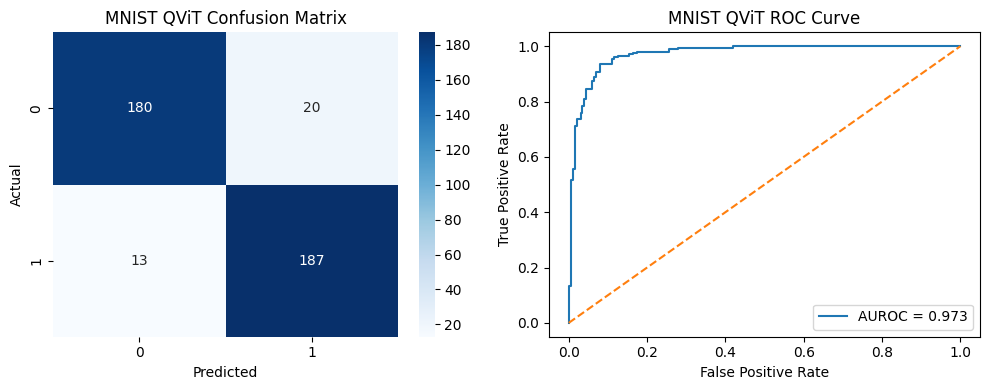

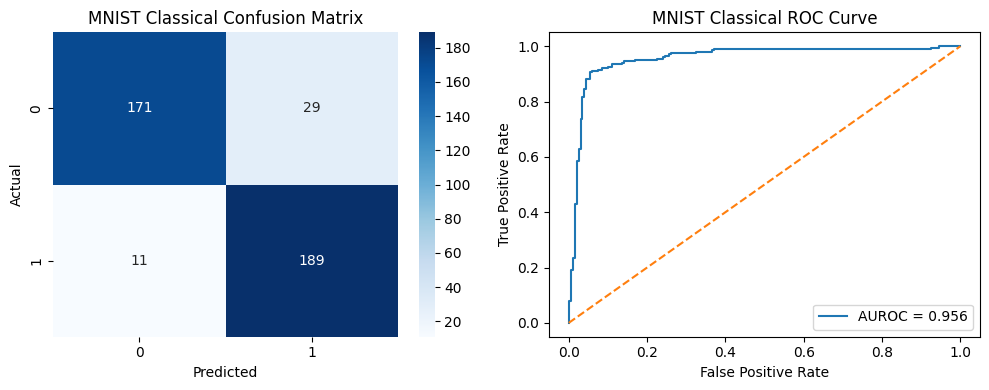

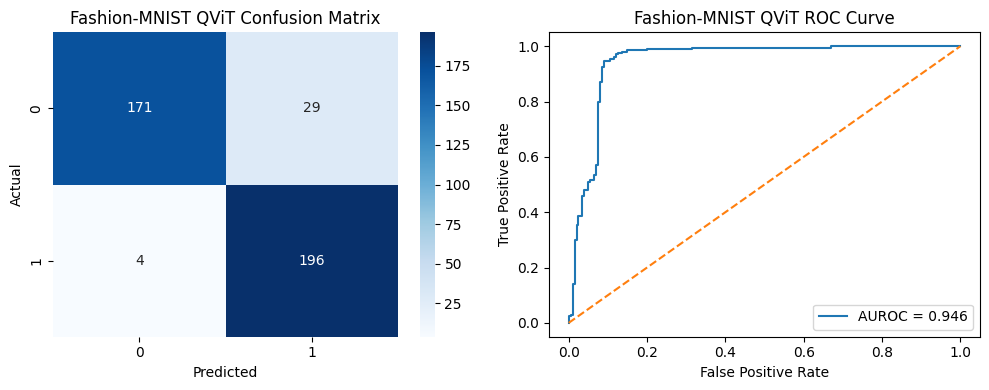

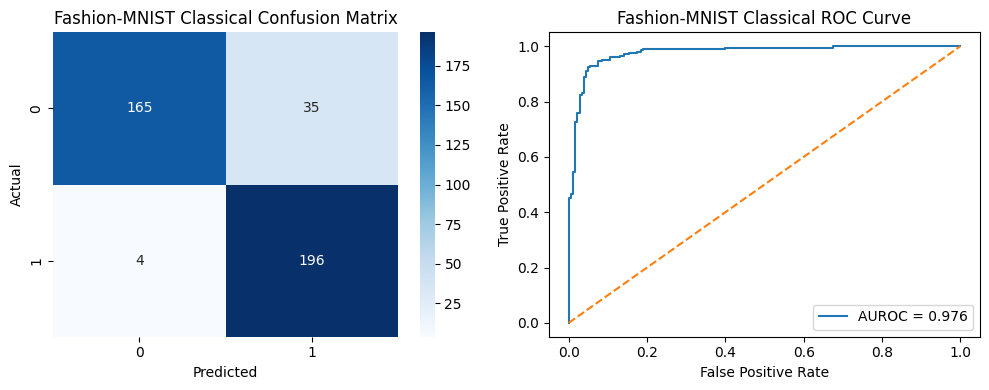

In [12]:
# Cell 11 — Confusion matrices and ROC curves
def plot_evaluation(result, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    cm = confusion_matrix(result["y_true"], result["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
    axes[0].set_title(title + " Confusion Matrix")
    axes[0].set_xlabel("Predicted")
    axes[0].set_ylabel("Actual")

    fpr, tpr, _ = roc_curve(result["y_true"], result["y_score"])
    axes[1].plot(fpr, tpr, label=f"AUROC = {result['AUROC']:.3f}")
    axes[1].plot([0, 1], [0, 1], linestyle="--")
    axes[1].set_title(title + " ROC Curve")
    axes[1].set_xlabel("False Positive Rate")
    axes[1].set_ylabel("True Positive Rate")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_evaluation(mnist_q_eval, "MNIST QViT")
plot_evaluation(mnist_c_eval, "MNIST Classical")
plot_evaluation(fashion_q_eval, "Fashion-MNIST QViT")
plot_evaluation(fashion_c_eval, "Fashion-MNIST Classical")

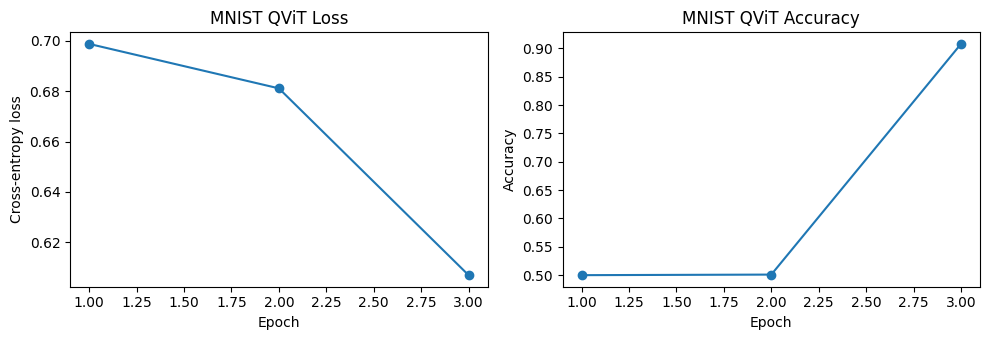

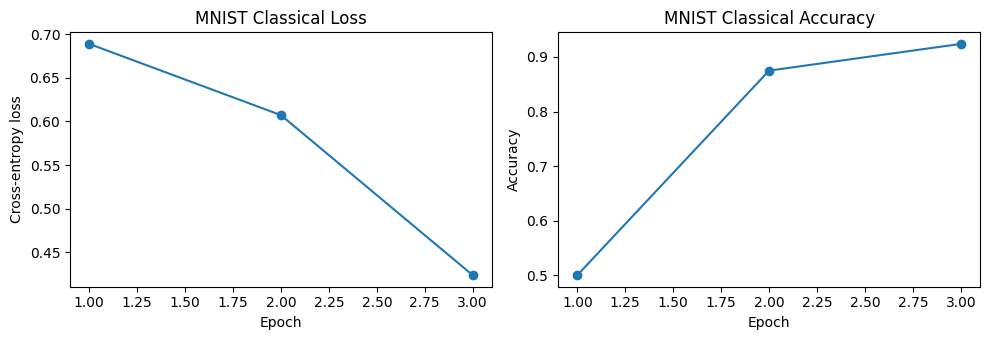

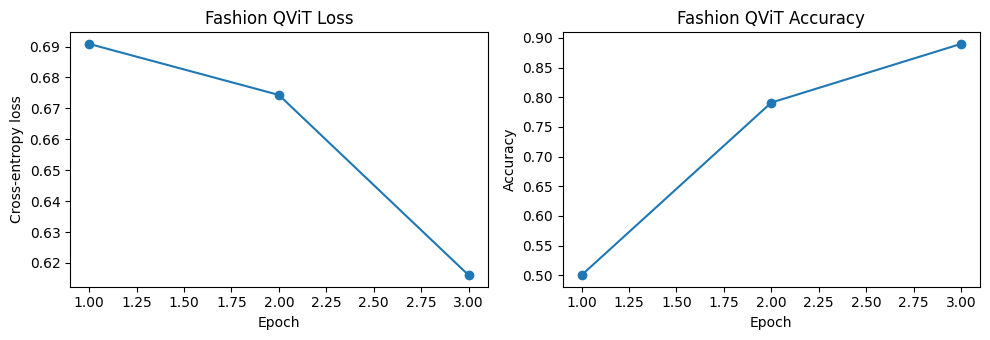

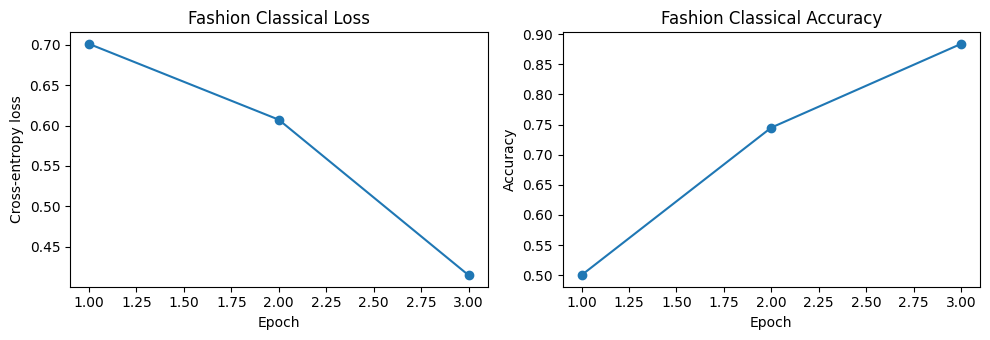

In [13]:
# Cell 12 — Training curves
def plot_training(losses, accuracies, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(range(1, len(losses)+1), losses, marker="o")
    axes[0].set_title(title + " Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Cross-entropy loss")

    axes[1].plot(range(1, len(accuracies)+1), accuracies, marker="o")
    axes[1].set_title(title + " Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    plt.tight_layout()
    plt.show()

plot_training(m_q_loss, m_q_acc, "MNIST QViT")
plot_training(m_c_loss, m_c_acc, "MNIST Classical")
plot_training(f_q_loss, f_q_acc, "Fashion QViT")
plot_training(f_c_loss, f_c_acc, "Fashion Classical")

## Quantum resource accounting

This notebook uses PennyLane's `default.qubit` **analytic simulator** (`shots=None`). Therefore, shots are reported as `None` / analytic, not as a finite-shot hardware experiment. Circuit depth is queried from PennyLane's circuit resource specification. Circuit evaluation counts below are **logical per-example circuit instances estimated from the number of examples processed**, not a count of physical hardware jobs or gate shots.

In [14]:
# Cell 13 — Quantum circuit depth and resource summary
sample_inputs = torch.zeros(N_QUBITS)
sample_weights = torch.zeros(N_QUANTUM_LAYERS, N_QUBITS, 3)

try:
    circuit_info = qml.specs(quantum_circuit)(sample_inputs, sample_weights)
    circuit_depth = circuit_info["resources"].depth
    gate_count = circuit_info["resources"].num_gates
except Exception as error:
    circuit_depth = np.nan
    gate_count = np.nan
    print("Could not extract circuit resources in this PennyLane version:", error)

# Each training example is processed once per epoch; each test example once.
mnist_train_count = len(mnist_train)
mnist_test_count = len(mnist_test)
fashion_train_count = len(fashion_train)
fashion_test_count = len(fashion_test)

quantum_cost_rows = [
    {
        "Dataset": "MNIST",
        "Qubits": N_QUBITS,
        "Quantum Layers": N_QUANTUM_LAYERS,
        "Circuit Depth (PennyLane)": circuit_depth,
        "Gate Count": gate_count,
        "Shots": "Analytic (shots=None)",
        "Estimated Training Circuit Instances": mnist_train_count * EPOCHS,
        "Estimated Inference Circuit Instances": mnist_test_count,
        "Model Training Time (s)": m_q_time,
        "Model Inference Time (s)": mnist_q_eval["Inference Time (s)"]
    },
    {
        "Dataset": "Fashion-MNIST",
        "Qubits": N_QUBITS,
        "Quantum Layers": N_QUANTUM_LAYERS,
        "Circuit Depth (PennyLane)": circuit_depth,
        "Gate Count": gate_count,
        "Shots": "Analytic (shots=None)",
        "Estimated Training Circuit Instances": fashion_train_count * EPOCHS,
        "Estimated Inference Circuit Instances": fashion_test_count,
        "Model Training Time (s)": f_q_time,
        "Model Inference Time (s)": fashion_q_eval["Inference Time (s)"]
    }
]
quantum_cost_df = pd.DataFrame(quantum_cost_rows)
display(quantum_cost_df)

,Dataset,Qubits,Quantum Layers,Circuit Depth (PennyLane),Gate Count,Shots,Estimated Training Circuit Instances,Estimated Inference Circuit Instances,Model Training Time (s),Model Inference Time (s)
0,MNIST,4,2,2,2,Analytic (shots=None),3000,400,2.397843,0.154279
1,Fashion-MNIST,4,2,2,2,Analytic (shots=None),3000,400,2.603300,0.148566


In [15]:
# Cell 14 — Model comparison table
comparison_rows = [
    {"Dataset": "MNIST", "Model": "QViT", **{k: mnist_q_eval[k] for k in [
        "Accuracy", "Balanced Accuracy", "Macro-F1", "AUROC",
        "Inference Time (s)", "Latency (ms/image)"
    ]}, "Training Time (s)": m_q_time},
    {"Dataset": "MNIST", "Model": "Classical ViT", **{k: mnist_c_eval[k] for k in [
        "Accuracy", "Balanced Accuracy", "Macro-F1", "AUROC",
        "Inference Time (s)", "Latency (ms/image)"
    ]}, "Training Time (s)": m_c_time},
    {"Dataset": "Fashion-MNIST", "Model": "QViT", **{k: fashion_q_eval[k] for k in [
        "Accuracy", "Balanced Accuracy", "Macro-F1", "AUROC",
        "Inference Time (s)", "Latency (ms/image)"
    ]}, "Training Time (s)": f_q_time},
    {"Dataset": "Fashion-MNIST", "Model": "Classical ViT", **{k: fashion_c_eval[k] for k in [
        "Accuracy", "Balanced Accuracy", "Macro-F1", "AUROC",
        "Inference Time (s)", "Latency (ms/image)"
    ]}, "Training Time (s)": f_c_time}
]

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

,Dataset,Model,Accuracy,Balanced Accuracy,Macro-F1,AUROC,Inference Time (s),Latency (ms/image),Training Time (s)
0,MNIST,QViT,0.9175,0.9175,0.917475,0.972525,0.154279,0.385696,2.397843
1,MNIST,Classical ViT,0.9000,0.9000,0.899797,0.956050,0.014014,0.035035,0.337972
2,Fashion-MNIST,QViT,0.9175,0.9175,0.917176,0.945550,0.148566,0.371416,2.603300
3,Fashion-MNIST,Classical ViT,0.9025,0.9025,0.901911,0.976425,0.011326,0.028314,0.490721


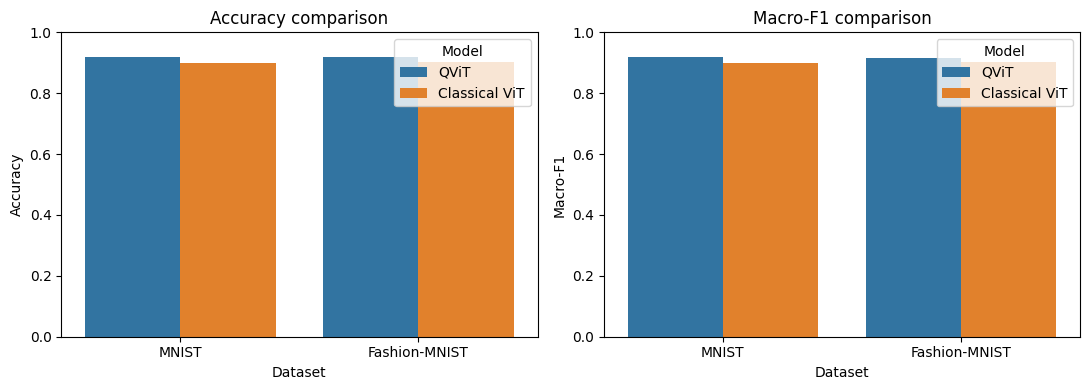

In [16]:
# Cell 15 — Comparison plots
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=comparison_df, x="Dataset", y="Accuracy", hue="Model", ax=axes[0])
axes[0].set_title("Accuracy comparison")
axes[0].set_ylim(0, 1)

sns.barplot(data=comparison_df, x="Dataset", y="Macro-F1", hue="Model", ax=axes[1])
axes[1].set_title("Macro-F1 comparison")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [17]:
# Cell 16 — Save result CSV files
# Dataset-specific model results
mnist_results_df = comparison_df[comparison_df["Dataset"] == "MNIST"].copy()
fashion_results_df = comparison_df[comparison_df["Dataset"] == "Fashion-MNIST"].copy()

mnist_results_df.to_csv("MNIST_QViT_Results.csv", index=False)
fashion_results_df.to_csv("Fashion_MNIST_QViT_Results.csv", index=False)
quantum_cost_df.to_csv("Quantum_Cost_Analysis.csv", index=False)
comparison_df.to_csv("QViT_Classical_Comparison.csv", index=False)

print("Saved:")
for filename in [
    "MNIST_QViT_Results.csv",
    "Fashion_MNIST_QViT_Results.csv",
    "Quantum_Cost_Analysis.csv",
    "QViT_Classical_Comparison.csv"
]:
    print(" -", filename)

Saved:
 - MNIST_QViT_Results.csv
 - Fashion_MNIST_QViT_Results.csv
 - Quantum_Cost_Analysis.csv
 - QViT_Classical_Comparison.csv


In [18]:
# Cell 17 — Final summary
print("========== FINAL EXPERIMENT SUMMARY ==========")
print("MNIST QViT accuracy:", round(mnist_q_eval["Accuracy"], 4))
print("MNIST Classical accuracy:", round(mnist_c_eval["Accuracy"], 4))
print("Fashion-MNIST QViT accuracy:", round(fashion_q_eval["Accuracy"], 4))
print("Fashion-MNIST Classical accuracy:", round(fashion_c_eval["Accuracy"], 4))
print("\nQuantum simulator: PennyLane default.qubit")
print("Qubits:", N_QUBITS)
print("Trainable quantum layers:", N_QUANTUM_LAYERS)
print("Shots: analytic (shots=None)")
print("Circuit depth:", circuit_depth)
print("\nUse the tables above for your report. Do not report these subset results as full-dataset results.")
print("For stronger research conclusions, repeat with larger subsets, more epochs, and multiple random seeds.")

========== FINAL EXPERIMENT SUMMARY ==========
MNIST QViT accuracy: 0.9175
MNIST Classical accuracy: 0.9
Fashion-MNIST QViT accuracy: 0.9175
Fashion-MNIST Classical accuracy: 0.9025

Quantum simulator: PennyLane default.qubit
Qubits: 4
Trainable quantum layers: 2
Shots: analytic (shots=None)
Circuit depth: 2

Use the tables above for your report. Do not report these subset results as full-dataset results.
For stronger research conclusions, repeat with larger subsets, more epochs, and multiple random seeds.


## Research reporting notes and limitations

1. **Subset experiment:** The default run uses a balanced subset of the official train and test splits. State the exact sample counts in your report.
2. **Fair comparison:** Both models receive identical resized 4×4 images and use the same train/test examples. The classical baseline does not include the quantum block.
3. **Quantum component:** The variational circuit is simulated using PennyLane `default.qubit`; no physical quantum hardware is used.
4. **Circuit evaluations:** The table reports estimated logical per-example circuit instances based on samples processed. PennyLane may batch or internally execute these differently.
5. **Circuit depth:** The reported depth is the depth of the standalone quantum circuit as reported by PennyLane, not the depth of the entire hybrid neural network.
6. **Latency:** Timings depend on the Colab runtime, batch size, and simulator. Compare models in the same runtime and report the conditions.
7. **Model scope:** This is a compact QViT-style research prototype. The self-attention calculation is classical; quantum processing enhances the pooled attention representation.
8. **Reference:** Fan et al. (2026), *Quantum circuit-based learning models: bridging quantum computing and machine learning*, Artificial Intelligence Review. DOI: 10.1007/s10462-026-11686-4. Treat this as background literature, not proof that this exact architecture appears in the paper.

### Suggested report sections
Abstract; Introduction; Related Work; Problem Statement; Dataset Description; Preprocessing; Proposed Hybrid Architecture; Classical Attention; Quantum Circuit; Experimental Setup; Evaluation Metrics; Results; Quantum Resource Analysis; Limitations; Future Work; Conclusion.